In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [29]:
import numpy as np
import os
import joblib
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score,
    f1_score
)

from collections import Counter

In [4]:
processed_path = '/content/drive/MyDrive/DataSets/Image dataset/Processed'

train_data = np.load(os.path.join(processed_path, 'train_data.npz'))
validation_data = np.load(os.path.join(processed_path, 'validation_data.npz'))
test_data = np.load(os.path.join(processed_path, 'test_data.npz'))

# Labels
Y_train = train_data['y']
Y_validation = validation_data['y']
Y_test = test_data['y']

# HOG Features
X_train_hog = train_data['X_hog']
X_validation_hog = validation_data['X_hog']
X_test_hog = test_data['X_hog']

# Color Histogram Features
X_train_color = train_data['X_color']
X_validation_color = validation_data['X_color']
X_test_color = test_data['X_color']

# Raw Pixels Features
X_train_raw = train_data['X_raw']
X_validation_raw = validation_data['X_raw']
X_test_raw = test_data['X_raw']

print("Dataset loaded successfully!")
print("Train:", len(Y_train))
print("Validation:", len(Y_validation))
print("Test:", len(Y_test))

Dataset loaded successfully!
Train: 3021
Validation: 648
Test: 648


In [5]:
print("HOG Features:")
print("Train:", X_train_hog.shape)
print("Validation:", X_validation_hog.shape)
print("Test:", X_test_hog.shape)

print("\nColor Histogram Features:")
print("Train:", X_train_color.shape)
print("Validation:", X_validation_color.shape)
print("Test:", X_test_color.shape)

print("\nRaw Pixels Features:")
print("Train:", X_train_raw.shape)
print("Validation:", X_validation_raw.shape)
print("Test:", X_test_raw.shape)

print("\nLabels:")
print("Train:", Y_train.shape)
print("Validation:", Y_validation.shape)
print("Test:", Y_test.shape)

HOG Features:
Train: (3021, 1764)
Validation: (648, 1764)
Test: (648, 1764)

Color Histogram Features:
Train: (3021, 96)
Validation: (648, 96)
Test: (648, 96)

Raw Pixels Features:
Train: (3021, 12288)
Validation: (648, 12288)
Test: (648, 12288)

Labels:
Train: (3021,)
Validation: (648,)
Test: (648,)


In [6]:
hog_scaler = StandardScaler()

X_train_hog_scaled = hog_scaler.fit_transform(X_train_hog)

X_validation_hog_scaled = hog_scaler.transform(X_validation_hog)

X_test_hog_scaled = hog_scaler.transform(X_test_hog)

print("HOG Scaling completed successfully!")

print("Training Mean:", X_train_hog_scaled.mean())
print("Training Standard Deviation:", X_train_hog_scaled.std())

HOG Scaling completed successfully!
Training Mean: -1.8325284e-10
Training Standard Deviation: 1.0


In [7]:
hog_lr_results = []

C_values = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]

for c in C_values:

    model = LogisticRegression(
        C=c,
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train_hog_scaled, Y_train)

    val_predictions = model.predict(X_validation_hog_scaled)

    accuracy = accuracy_score(Y_validation, val_predictions)

    hog_lr_results.append({
        'C': c,
        'Validation Accuracy': accuracy
    })

    print(f"C = {c} | Validation Accuracy = {accuracy:.4f}")

hog_lr_results_df = pd.DataFrame(hog_lr_results)

display(hog_lr_results_df)

C = 1e-05 | Validation Accuracy = 0.3287
C = 0.0001 | Validation Accuracy = 0.4198
C = 0.001 | Validation Accuracy = 0.3858
C = 0.01 | Validation Accuracy = 0.3503
C = 0.1 | Validation Accuracy = 0.3272
C = 1 | Validation Accuracy = 0.3133
C = 10 | Validation Accuracy = 0.3086


,C,Validation Accuracy
0,0.00001,0.328704
1,0.00010,0.419753
2,0.00100,0.385802
3,0.01000,0.350309
4,0.10000,0.327160
5,1.00000,0.313272
6,10.00000,0.308642


In [8]:
best_hog_lr_C = hog_lr_results_df.loc[
    hog_lr_results_df['Validation Accuracy'].idxmax(), 'C'
]

print("Best HOG Logistic Regression C:", best_hog_lr_C)

Best HOG Logistic Regression C: 0.0001


In [9]:
hog_knn_results = []

K_values = [1, 3, 5, 7, 9, 11, 15, 21]

for k in K_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_hog_scaled, Y_train)

    val_predictions = model.predict(X_validation_hog_scaled)

    accuracy = accuracy_score(Y_validation, val_predictions)

    hog_knn_results.append({
        'K': k,
        'Validation Accuracy': accuracy
    })

    print(f"K = {k} | Validation Accuracy = {accuracy:.4f}")

hog_knn_results_df = pd.DataFrame(hog_knn_results)

display(hog_knn_results_df)

K = 1 | Validation Accuracy = 0.3241
K = 3 | Validation Accuracy = 0.2994
K = 5 | Validation Accuracy = 0.2809
K = 7 | Validation Accuracy = 0.2948
K = 9 | Validation Accuracy = 0.2840
K = 11 | Validation Accuracy = 0.2917
K = 15 | Validation Accuracy = 0.3009
K = 21 | Validation Accuracy = 0.2994


,K,Validation Accuracy
0,1,0.324074
1,3,0.299383
2,5,0.280864
3,7,0.294753
4,9,0.283951
5,11,0.291667
6,15,0.300926
7,21,0.299383


In [10]:
best_hog_knn_k = hog_knn_results_df.loc[
    hog_knn_results_df['Validation Accuracy'].idxmax(), 'K'
]

print("Best HOG KNN K:", best_hog_knn_k)

Best HOG KNN K: 1


In [11]:
hog_kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

hog_train_clusters = hog_kmeans.fit_predict(X_train_hog_scaled)

hog_val_clusters = hog_kmeans.predict(X_validation_hog_scaled)

hog_silhouette = silhouette_score(
    X_train_hog_scaled,
    hog_train_clusters
)

print("HOG K-Means Silhouette Score:", hog_silhouette)

HOG K-Means Silhouette Score: 0.01227188


In [12]:
hog_cluster_mapping = {}

for cluster in range(5):

    cluster_labels = Y_train[hog_train_clusters == cluster]

    if len(cluster_labels) > 0:
        most_common_class = Counter(cluster_labels).most_common(1)[0][0]

        hog_cluster_mapping[cluster] = most_common_class

print("HOG Cluster Mapping:")
print(hog_cluster_mapping)

HOG Cluster Mapping:
{0: np.str_('sunflower'), 1: np.str_('daisy'), 2: np.str_('tulip'), 3: np.str_('dandelion'), 4: np.str_('dandelion')}


In [13]:
hog_val_predictions = np.array([
    hog_cluster_mapping[cluster]
    for cluster in hog_val_clusters
])

hog_kmeans_val_accuracy = accuracy_score(
    Y_validation,
    hog_val_predictions
)

print("HOG K-Means Validation Accuracy:",
      hog_kmeans_val_accuracy)

HOG K-Means Validation Accuracy: 0.29475308641975306


In [14]:
color_scaler = StandardScaler()

X_train_color_scaled = color_scaler.fit_transform(X_train_color)

X_validation_color_scaled = color_scaler.transform(X_validation_color)

X_test_color_scaled = color_scaler.transform(X_test_color)

print("Color Histogram Scaling completed successfully!")

print("Training Mean:", X_train_color_scaled.mean())
print("Training Standard Deviation:", X_train_color_scaled.std())

Color Histogram Scaling completed successfully!
Training Mean: 7.938039500795559e-18
Training Standard Deviation: 0.9999999999999993


In [15]:
color_lr_results = []

C_values = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]

for c in C_values:

    model = LogisticRegression(
        C=c,
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train_color_scaled, Y_train)

    val_predictions = model.predict(X_validation_color_scaled)

    accuracy = accuracy_score(Y_validation, val_predictions)

    color_lr_results.append({
        'C': c,
        'Validation Accuracy': accuracy
    })

    print(f"C = {c} | Validation Accuracy = {accuracy:.4f}")

color_lr_results_df = pd.DataFrame(color_lr_results)

display(color_lr_results_df)

C = 1e-05 | Validation Accuracy = 0.2454
C = 0.0001 | Validation Accuracy = 0.3472
C = 0.001 | Validation Accuracy = 0.4306
C = 0.01 | Validation Accuracy = 0.4414
C = 0.1 | Validation Accuracy = 0.4321
C = 1 | Validation Accuracy = 0.4321
C = 10 | Validation Accuracy = 0.4321


,C,Validation Accuracy
0,0.00001,0.245370
1,0.00010,0.347222
2,0.00100,0.430556
3,0.01000,0.441358
4,0.10000,0.432099
5,1.00000,0.432099
6,10.00000,0.432099


In [16]:
best_color_lr_C = color_lr_results_df.loc[
    color_lr_results_df['Validation Accuracy'].idxmax(), 'C'
]

print("Best Color Logistic Regression C:", best_color_lr_C)

Best Color Logistic Regression C: 0.01


In [17]:
color_knn_results = []

K_values = [1, 3, 5, 7, 9, 11, 15, 21]

for k in K_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_color_scaled, Y_train)

    val_predictions = model.predict(X_validation_color_scaled)

    accuracy = accuracy_score(Y_validation, val_predictions)

    color_knn_results.append({
        'K': k,
        'Validation Accuracy': accuracy
    })

    print(f"K = {k} | Validation Accuracy = {accuracy:.4f}")

color_knn_results_df = pd.DataFrame(color_knn_results)

display(color_knn_results_df)

K = 1 | Validation Accuracy = 0.3843
K = 3 | Validation Accuracy = 0.3951
K = 5 | Validation Accuracy = 0.3889
K = 7 | Validation Accuracy = 0.4074
K = 9 | Validation Accuracy = 0.4275
K = 11 | Validation Accuracy = 0.4414
K = 15 | Validation Accuracy = 0.4167
K = 21 | Validation Accuracy = 0.4367


,K,Validation Accuracy
0,1,0.384259
1,3,0.395062
2,5,0.388889
3,7,0.407407
4,9,0.427469
5,11,0.441358
6,15,0.416667
7,21,0.436728


In [18]:
best_color_knn_k = color_knn_results_df.loc[
    color_knn_results_df['Validation Accuracy'].idxmax(), 'K'
]

print("Best Color KNN K:", best_color_knn_k)

Best Color KNN K: 11


In [19]:
color_kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

color_train_clusters = color_kmeans.fit_predict(X_train_color_scaled)

color_val_clusters = color_kmeans.predict(X_validation_color_scaled)

color_silhouette = silhouette_score(
    X_train_color_scaled,
    color_train_clusters
)

print("Color K-Means Silhouette Score:", color_silhouette)

Color K-Means Silhouette Score: 0.08065843814093578


In [20]:
color_cluster_mapping = {}

for cluster in range(5):

    cluster_labels = Y_train[color_train_clusters == cluster]

    if len(cluster_labels) > 0:
        most_common_class = Counter(cluster_labels).most_common(1)[0][0]

        color_cluster_mapping[cluster] = most_common_class

print("Color Cluster Mapping:")
print(color_cluster_mapping)

Color Cluster Mapping:
{0: np.str_('dandelion'), 1: np.str_('dandelion'), 2: np.str_('tulip'), 3: np.str_('dandelion'), 4: np.str_('sunflower')}


In [21]:
color_val_predictions = np.array([
    color_cluster_mapping[cluster]
    for cluster in color_val_clusters
])

color_kmeans_val_accuracy = accuracy_score(
    Y_validation,
    color_val_predictions
)

print("Color K-Means Validation Accuracy:",
      color_kmeans_val_accuracy)

Color K-Means Validation Accuracy: 0.2824074074074074


In [22]:
best_hog_lr = LogisticRegression(
    C=best_hog_lr_C,
    max_iter=2000,
    random_state=42
)

best_hog_lr.fit(X_train_hog_scaled, Y_train)

best_hog_knn = KNeighborsClassifier(
    n_neighbors=int(best_hog_knn_k)
)

best_hog_knn.fit(X_train_hog_scaled, Y_train)

print("Final HOG models trained successfully!")

Final HOG models trained successfully!


In [23]:
best_color_lr = LogisticRegression(
    C=best_color_lr_C,
    max_iter=2000,
    random_state=42
)

best_color_lr.fit(X_train_color_scaled, Y_train)

best_color_knn = KNeighborsClassifier(
    n_neighbors=int(best_color_knn_k)
)

best_color_knn.fit(X_train_color_scaled, Y_train)

print("Final Color models trained successfully!")

Final Color models trained successfully!


In [24]:
hog_lr_test_predictions = best_hog_lr.predict(X_test_hog_scaled)

hog_knn_test_predictions = best_hog_knn.predict(X_test_hog_scaled)

color_lr_test_predictions = best_color_lr.predict(X_test_color_scaled)

color_knn_test_predictions = best_color_knn.predict(X_test_color_scaled)

hog_kmeans_test_clusters = hog_kmeans.predict(X_test_hog_scaled)

hog_kmeans_test_predictions = np.array([
    hog_cluster_mapping[cluster]
    for cluster in hog_kmeans_test_clusters
])

color_kmeans_test_clusters = color_kmeans.predict(X_test_color_scaled)

color_kmeans_test_predictions = np.array([
    color_cluster_mapping[cluster]
    for cluster in color_kmeans_test_clusters
])

print("All test predictions completed!")

All test predictions completed!


In [25]:
test_predictions = {
    "HOG Logistic Regression": hog_lr_test_predictions,
    "HOG KNN": hog_knn_test_predictions,
    "HOG K-Means": hog_kmeans_test_predictions,
    "Color Logistic Regression": color_lr_test_predictions,
    "Color KNN": color_knn_test_predictions,
    "Color K-Means": color_kmeans_test_predictions
}

for model_name, predictions in test_predictions.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(classification_report(
        Y_test,
        predictions,
        zero_division=0
    ))


HOG Logistic Regression
              precision    recall  f1-score   support

       daisy       0.37      0.23      0.29       115
   dandelion       0.38      0.51      0.43       158
        rose       0.44      0.29      0.35       117
   sunflower       0.36      0.28      0.31       110
       tulip       0.41      0.54      0.47       148

    accuracy                           0.39       648
   macro avg       0.39      0.37      0.37       648
weighted avg       0.39      0.39      0.38       648


HOG KNN
              precision    recall  f1-score   support

       daisy       0.26      0.14      0.18       115
   dandelion       0.37      0.38      0.38       158
        rose       0.20      0.08      0.11       117
   sunflower       0.20      0.29      0.24       110
       tulip       0.30      0.45      0.36       148

    accuracy                           0.28       648
   macro avg       0.27      0.27      0.25       648
weighted avg       0.28      0.28      0.27

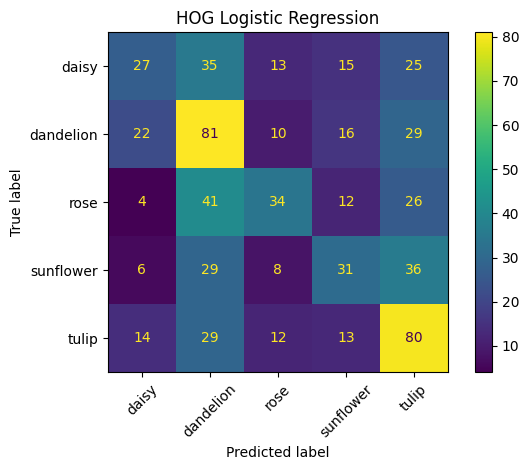

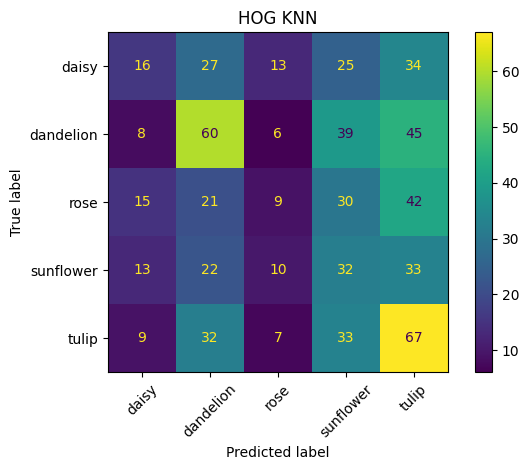

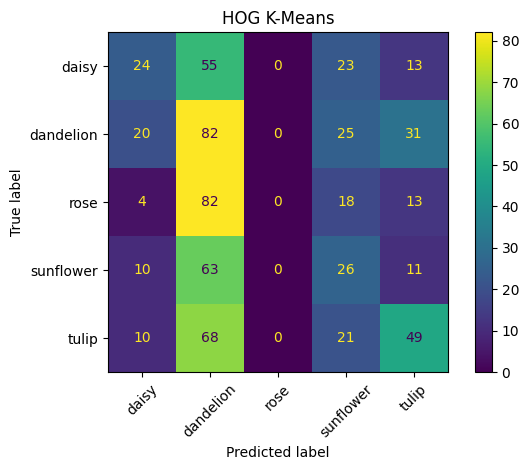

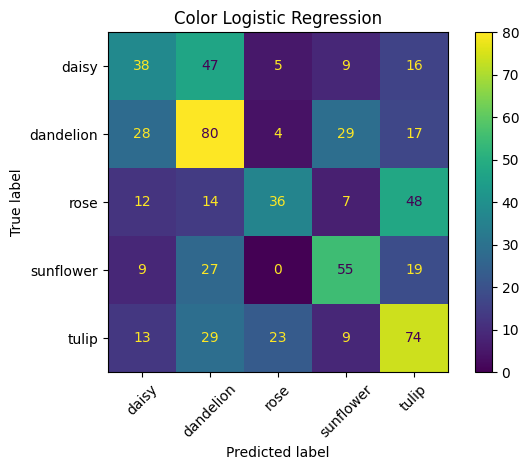

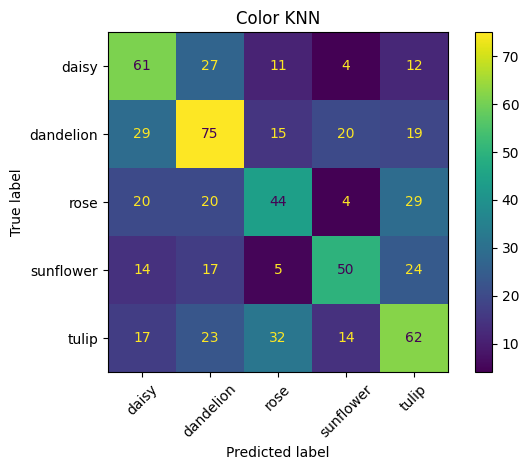

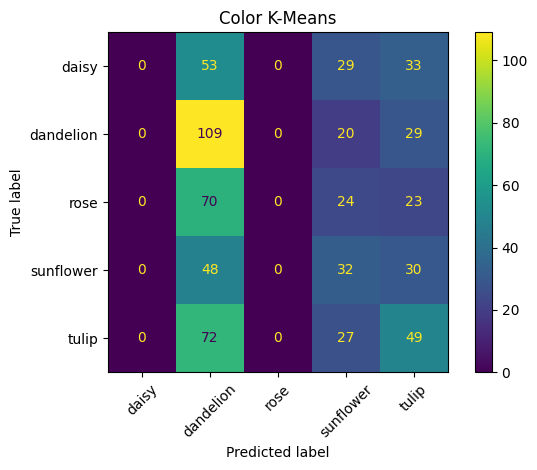

In [26]:
for model_name, predictions in test_predictions.items():

    cm = confusion_matrix(
        Y_test,
        predictions,
        labels=['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
    )

    display_cm.plot(xticks_rotation=45)

    plt.title(model_name)
    plt.tight_layout()
    plt.show()

In [27]:
final_results = []

for model_name, predictions in test_predictions.items():

    accuracy = accuracy_score(Y_test, predictions)

    macro_f1 = f1_score(
        Y_test,
        predictions,
        average='macro'
    )

    final_results.append({
        'Model': model_name,
        'Test Accuracy': accuracy,
        'Macro F1': macro_f1
    })

final_comparison_df = pd.DataFrame(final_results)

display(
    final_comparison_df.sort_values(
        by='Test Accuracy',
        ascending=False
    )
)

,Model,Test Accuracy,Macro F1
4,Color KNN,0.450617,0.450998
3,Color Logistic Regression,0.436728,0.431058
0,HOG Logistic Regression,0.390432,0.370381
5,Color K-Means,0.293210,0.201203
1,HOG KNN,0.283951,0.253798
2,HOG K-Means,0.279321,0.237625


In [30]:
# Create Models folder
models_path = os.path.join(processed_path, "Models")
os.makedirs(models_path, exist_ok=True)

# Save trained models
joblib.dump(best_color_knn, os.path.join(models_path, "color_knn_model.pkl"))
joblib.dump(best_color_lr, os.path.join(models_path, "color_lr_model.pkl"))

# Save scaler
joblib.dump(color_scaler, os.path.join(models_path, "color_scaler.pkl"))

# Save class names
class_names = np.unique(Y_train)
joblib.dump(class_names, os.path.join(models_path, "class_names.pkl"))

print("Image models saved successfully!")
print("\nSaved files:")
for file in os.listdir(models_path):
    print("-", file)

Image models saved successfully!

Saved files:
- color_knn_model.pkl
- color_lr_model.pkl
- color_scaler.pkl
- class_names.pkl
